# StepFree NYC — exploratory analysis and result checks

This notebook profiles the five provided datasets, shows why the accessibility-investment problem is worth solving, and re-derives the headline results from the pipeline module. Run `./run_all.sh` first so `outputs/` exists.

In [1]:
import sys, json
sys.path.insert(0, '../pipeline')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from stepfree import DATA, OUT, build_problem, greedy, gap_index, exact_milp, haversine_matrix
pd.set_option('display.width', 160)

## 1. Data audit

In [2]:
rid = pd.read_csv(DATA / 'mta_station_daily_aug_sep_2025.csv', parse_dates=['service_date'])
acc = pd.read_csv(DATA / 'mta_station_accessibility_current.csv')
wx  = pd.read_csv(DATA / 'noaa_daily_weather_aug_sep_2025.csv', parse_dates=['DATE'])
sr  = pd.read_csv(DATA / 'nyc311_dot_aug_sep_2025.csv')
cr  = pd.read_csv(DATA / 'nyc_crashes_aug_sep_2025.csv')
for name, df in [('ridership', rid), ('accessibility', acc), ('weather', wx), ('311', sr), ('crashes', cr)]:
    print(f'{name:14s} rows={len(df):6d} cols={df.shape[1]:2d} missing cells={int(df.isna().sum().sum()):5d} duplicate rows={int(df.duplicated().sum())}')

ridership      rows= 25820 cols= 5 missing cells=    0 duplicate rows=0
accessibility  rows=   496 cols=19 missing cells=  488 duplicate rows=0
weather        rows=   183 cols= 6 missing cells=    0 duplicate rows=0
311            rows= 34676 cols=10 missing cells= 9489 duplicate rows=0
crashes        rows= 14526 cols= 9 missing cells= 3015 duplicate rows=0


In [3]:
print('Ridership date range:', rid.service_date.min().date(), '->', rid.service_date.max().date())
print('Complex-days present per date (min/max):', rid.groupby('service_date').size().agg(['min','max']).tolist())
print('Duplicate complex-day keys:', rid.duplicated(['service_date','station_complex_id']).sum())
print('Accessibility ADA codes (stop level):', acc.ada.value_counts().to_dict())
print('Complex IDs: ridership', rid.station_complex_id.nunique(), '| accessibility', acc.complex_id.nunique(),
      '| matched', len(set(rid.station_complex_id) & set(acc.complex_id)))
print('Accessibility complexes with no ridership (borough):', acc[~acc.complex_id.isin(rid.station_complex_id)].borough.value_counts().to_dict())

Ridership date range: 2025-08-01 -> 2025-09-30
Complex-days present per date (min/max): [419, 424]
Duplicate complex-day keys: 0
Accessibility ADA codes (stop level): {0: 322, 1: 166, 2: 8}
Complex IDs: ridership 424 | accessibility 445 | matched 424
Accessibility complexes with no ridership (borough): {'SI': 21}


Every ridership complex matches an accessibility complex. The 21 unmatched accessibility complexes are all Staten Island Railway (borough `SI`), which the subway ridership file does not cover, so Staten Island is out of scope.

## 2. Temporal pattern of demand

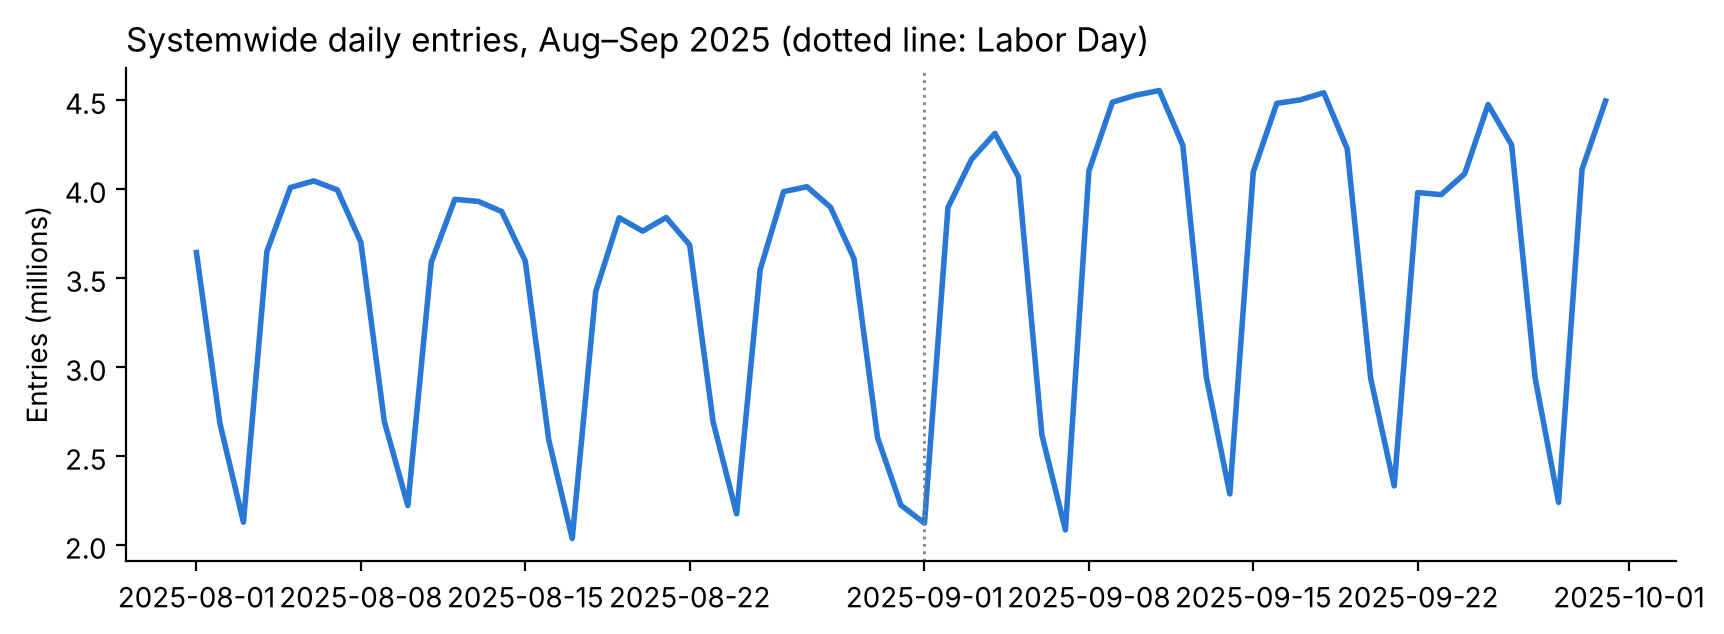

dow
Thursday     4.19
Wednesday    4.13
Tuesday      4.12
Friday       3.89
Monday       3.63
Saturday     2.75
Sunday       2.19
dtype: float64


In [4]:
daily = rid.groupby('service_date').entries.sum()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(daily.index, daily / 1e6, color='#2a78d6', lw=2)
ax.axvline(pd.Timestamp('2025-09-01'), color='#7c837b', ls=':', lw=1)
ax.set_ylabel('Entries (millions)'); ax.set_title('Systemwide daily entries, Aug–Sep 2025 (dotted line: Labor Day)', loc='left')
ax.spines[['top','right']].set_visible(False); plt.show()
dow = rid.assign(dow=rid.service_date.dt.day_name()).groupby('dow').entries.sum() / rid.groupby(rid.service_date.dt.day_name()).service_date.nunique()
print((dow / 1e6).round(2).sort_values(ascending=False))

Strong weekly cycle with weekday demand much higher than weekend, plus a September back-to-school rise. We therefore use **mean weekday entries (Labor Day excluded)** as the demand weight, and test August-vs-September and weekend weights as sensitivity checks.

## 3. The accessibility gap

In [5]:
st = pd.read_csv(OUT / 'stations_scored.csv')
by = st.groupby('status').agg(complexes=('complex_id','size'), weekday_entries=('w_weekday','sum'))
by['share_of_entries'] = (by.weekday_entries / by.weekday_entries.sum()).round(3)
by

,complexes,weekday_entries,share_of_entries
status,,,
full,120,2.011600e+06,0.499
none,290,1.672158e+06,0.415
partial,14,3.450077e+05,0.086


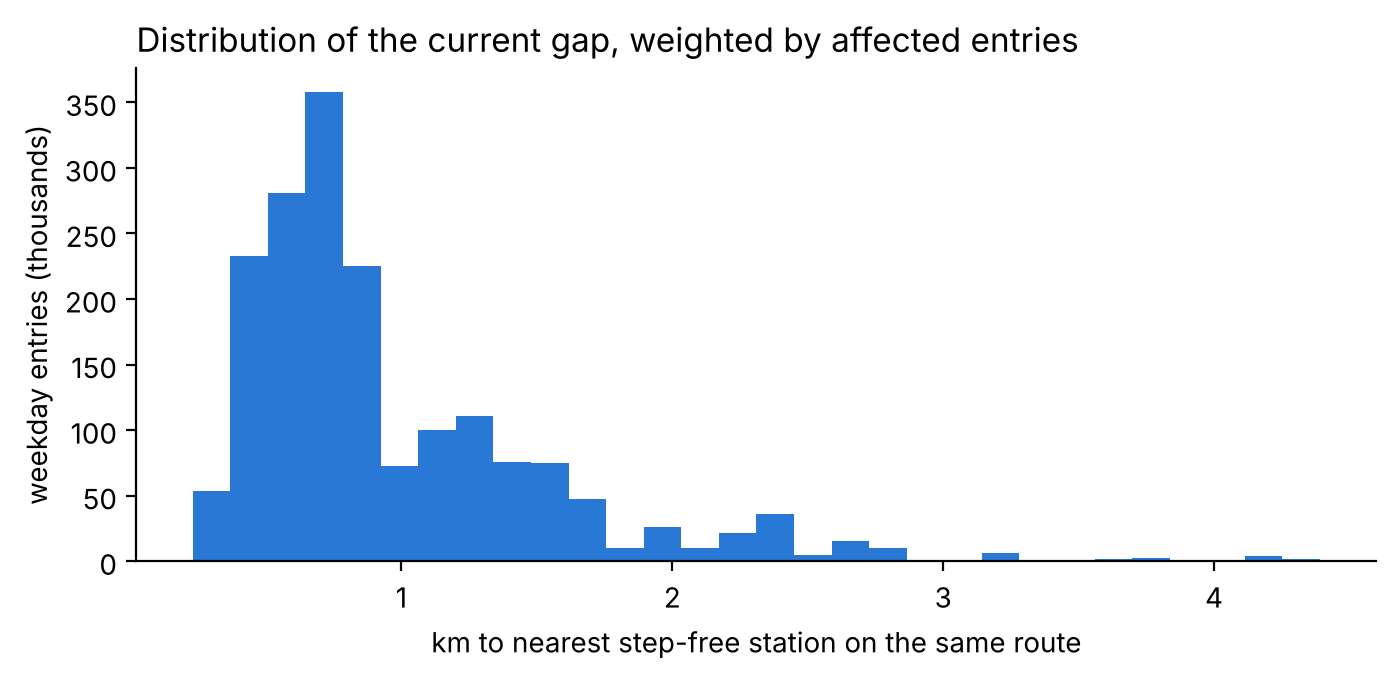

Entry-weighted mean gap: 0.97 km
Share of affected entries with gap > 1 km: 34.3%


In [6]:
p = build_problem(st, dist=haversine_matrix(st.lat.values, st.lon.values))
um = p.u > 0
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(p.d0[um], bins=30, weights=p.u[um] / 1000, color='#2a78d6')
ax.set_xlabel('km to nearest step-free station on the same route'); ax.set_ylabel('weekday entries (thousands)')
ax.set_title('Distribution of the current gap, weighted by affected entries', loc='left'); ax.spines[['top','right']].set_visible(False); plt.show()
print('Entry-weighted mean gap: %.2f km' % ((p.u * p.d0).sum() / p.u.sum()))
print('Share of affected entries with gap > 1 km: %.1f%%' % (100 * p.u[p.d0 > 1].sum() / p.u.sum()))

## 4. Does busiest-first leave value on the table?

In [7]:
B0 = gap_index(p)
opt = greedy(p, 20)
busy = list(p.cands[np.argsort(-st.w_weekday.values[p.cands])])[:20]
S, val, msg = exact_milp(p, 20)
print('Gap closed — optimiser: %.1f%% | busiest-first: %.1f%% | exact MILP: %.1f%% (%s)' % (
    100 * (1 - gap_index(p, opt) / B0), 100 * (1 - gap_index(p, busy) / B0), 100 * (1 - val / B0), msg))
print('Overlap of optimiser and busiest-first top 20:', len(set(opt) & set(busy)))
st.iloc[opt][['name','borough','w_weekday','d0']].assign(rank=range(1, 21)).set_index('rank').round(2)

Gap closed — optimiser: 33.8% | busiest-first: 18.9% | exact MILP: 33.8% (Optimization terminated successfully. (HiGHS Status 7: Optimal))
Overlap of optimiser and busiest-first top 20: 8


,name,borough,w_weekday,d0
rank,,,,
1,"Woodhaven Blvd (M,R)",Queens,14186.07,2.40
2,"86 St (C,B)",Manhattan,8363.57,2.24
3,Classon Av (G),Brooklyn,4080.38,2.84
4,"Broadway Junction (A,C,J,Z,L)",Brooklyn,6047.05,1.10
5,"36 St (D,N,R)",Brooklyn,11996.21,1.95
6,"Delancey St-Essex St (F,M,J,Z)",Manhattan,22168.24,1.02
7,Pennsylvania Av (3),Brooklyn,2623.21,3.24
8,"145 St (A,C,B,D)",Manhattan,16220.38,1.59
9,"Canal St (6,J,Z,N,Q,R,W)",Manhattan,36043.86,0.67


Why the two lists differ: a busy station that already sits a few hundred metres from a step-free station on the same route gains little from an elevator, while a moderately busy station on a line segment with no step-free stop for 2–3 km gains a lot — and one upgrade there also shortens the detour for its neighbours.

## 5. Validation summary (from `outputs/metrics.json`)

In [8]:
M = json.loads((OUT / 'metrics.json').read_text())
print(json.dumps({k: M[k] for k in ['out_of_sample', 'bootstrap', 'sensitivity_top20_overlap', 'equity_floor', 'borough_kruskal_wallis']}, indent=1))

{
 "out_of_sample": {
  "train": "Aug 2025 weekdays",
  "test": "Sep 2025 weekdays (excl. Labor Day)",
  "reduction_greedy_trained_on_aug": 0.33291580874601356,
  "reduction_oracle_trained_on_sep": 0.3359576609953171,
  "reduction_busiest_first_aug": 0.1819307796819638,
  "overlap_aug_plan_vs_sep_oracle": 16,
  "spearman_station_weights_aug_vs_sep": 0.9956924142599632,
  "sep_over_aug_total_weekday_entries": 1.1255560566030782
 },
 "bootstrap": {
  "replicates": 200,
  "greedy_top20_mean_selection_freq": 0.9754999999999999,
  "greedy_top20_selected_in_ge_90pct": 18,
  "stations_ever_selected": 23
 },
 "sensitivity_top20_overlap": {
  "any_route_alternative": {
   "overlap_of_20": 6,
   "reduction_own_objective": 0.3003271438666264
  },
  "strict_partial (one-direction ADA = not step-free)": {
   "overlap_of_20": 19,
   "reduction_own_objective": 0.343651079608301
  },
  "cap_3km": {
   "overlap_of_20": 20,
   "reduction_own_objective": 0.33356952056252187
  },
  "cap_8km": {
   "overla

## 6. Weather check
NOAA data is used only to ask whether rainy days distort the demand weights. Re-estimating weights on dry weekdays leaves the top 20 unchanged (see `sensitivity_top20_overlap.dry_weekday_weights`).

In [9]:
city = wx.groupby('DATE').PRCP.mean()
wk = rid[(rid.service_date.dt.day_of_week < 5) & (rid.service_date != '2025-09-01')]
tot = wk.groupby('service_date').entries.sum()
df = pd.DataFrame({'entries': tot, 'prcp': city.reindex(tot.index)})
df['wet'] = df.prcp >= 2.5
print(df.groupby('wet').entries.agg(['count','mean']).round(0))
print('Wet vs dry weekday mean entries: %+.1f%%' % (100 * (df[df.wet].entries.mean() / df[~df.wet].entries.mean() - 1)))
print('Wet weekdays by month:', df[df.wet].index.month.value_counts().to_dict())

       count       mean
wet                    
False     35  4007968.0
True       7  4132759.0
Wet vs dry weekday mean entries: +3.1%
Wet weekdays by month: {9: 4, 8: 3}


Wet weekdays show slightly *higher* systemwide entries, but more than half of them fall in September, when ridership rises for back-to-school, so this comparison is confounded and only 7 wet weekdays exist. We draw no weather conclusion. The point of the check is narrower: excluding wet days does not change which stations the planner picks.